# Skin Type Disorder Prediction Model¶

#  Project Workflow

1. Problem Statement
2. Introductuion
3. Dataset Description
4. Import Libraries
5. Load Dataset
6. Initial Data Exploration
7. Data Cleaning ├── Missing Values ├── Duplicate Values ├── Data Types ├── Invalid Values └── Inspection of Age
8. EDA
9. Data train_test_split
10. Why SMOTE is Used
11. Class Imbalance in Data
12. Improving Model Performance
13. Class Distribution plots (Countplot, Heatmap, Histograms, Boxplot, Pairplots, Barplots)
14. Choice of Models
15. Hyperparameter Tunning
16. Suggestions for Doctors
17. Model Comparision
18. Challenges Faced during the Prediction Model
19. Evaluation and Interpretation
20. Doctors Suggestion using Feature Importance
21. Conclusion

# Introduction

- Skin diseases represent a significant portion of global health concerns, affecting millions of individuals across diverse age groups and regions. Early detection and accurate classification of these conditions are crucial for effective treatment and improved patient outcomes. However, traditional diagnostic methods often rely heavily on clinical expertise, which can be subjective and time-consuming.

- This project aims to leverage data science and machine learning techniques to enhance the diagnosis and prediction of skin disorders. By analyzing dermatological datasets containing clinical attributes such as erythema, scaling, itching, and family history, the project seeks to uncover meaningful patterns and correlations that can assist in disease classification

# The Ojectives of this Project are as Follows:

- Task 1: Conduct a comprehensive data analysis report to understand the dataset, identify trends, and highlight key features.

- Task 2: Develop predictive models using machine learning algorithms to classify various types of skin diseases with high accuracy.

- Task 3: Provide actionable suggestions for doctors to support early identification and treatment of skin disorders.

Through this approach, the project not only demonstrates the practical application of machine learning in healthcare but also contributes to bridging the gap between technology and medical practice, ultimately aiming to improve patient care and diagnostic efficiency.


# Dataset Description

- The dataset contains 366 observations and 35 columns, consisting of 34 predictor attributes and one target variable.
The target variable, class, contains six disease classes. Most clinical and histopathological attributes are recorded on
an ordinal 0–3 scale.

# Features
The dataset contains 34 input features, which are divided into two categories:

Clinical Features (12 attributes)
Erythema , Scaling, Definite Borders, Itching, Koebner Phenomenon, Polygonal Papules, Follicular Papules, Oral Mucosal Involvement, Knee and Elbow Involvement, Scalp Involvement, Family History, Age

Histopathological Features (22 attributes) These describe microscopic skin tissue characteristics observed through biopsy, including:
Melanin Incontinence, Fibrosis, Acanthosis, Hyperkeratosis, Parakeratosis, Exocytosis, Spongiosis, Munro Microabscess, Focal Hypergranulosis, Vacuolisation, Band-like Infiltrate, Elongation of Rete Ridges, Clubbing of Rete Ridges, Thinning of Suprapapillary Epidermis, Others

Most clinical and histopathological features are recorded on an ordinal scale from 0 to 3, where:

0 = Feature absent, 1 = Mild, 2 = Moderate, 3 = Severe

# Importing Libraries

In [1]:
#Data Handling
import pandas as pd 
import numpy as np

#Data visulaization
import matplotlib.pyplot as plt
import seaborn as sns 
import warnings
warnings.filterwarnings('ignore')

#Machine learning
from sklearn.model_selection import train_test_split , GridSearchCV , RandomizedSearchCV
from sklearn.preprocessing import StandardScaler , LabelEncoder
from sklearn.metrics import classification_report, confusion_matrix , accuracy_score, roc_curve

#Models
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC


# Loading the Dataset

In [2]:
df=pd.read_csv("PRCP-1028-Skin-Disorder-Prediction-20220512T101734Z-001.zip")
df

,erythema,scaling,definite_borders,itching,koebner_phenomenon,polygonal_papules,follicular_papules,oral_mucosal_involvement,knee_and_elbow_involvement,scalp_involvement,...,disappearance_of_the_granular_layer,vacuolisation_and_damage_of_basal_layer,spongiosis,saw-tooth_appearance_of_retes,follicular_horn_plug,perifollicular_parakeratosis,inflammatory_monoluclear_inflitrate,band-like_infiltrate,Age,class
0,2,2,0,3,0,0,0,0,1,0,...,0,0,3,0,0,0,1,0,55,2
1,3,3,3,2,1,0,0,0,1,1,...,0,0,0,0,0,0,1,0,8,1
2,2,1,2,3,1,3,0,3,0,0,...,0,2,3,2,0,0,2,3,26,3
3,2,2,2,0,0,0,0,0,3,2,...,3,0,0,0,0,0,3,0,40,1
4,2,3,2,2,2,2,0,2,0,0,...,2,3,2,3,0,0,2,3,45,3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
361,2,1,1,0,1,0,0,0,0,0,...,0,0,1,0,0,0,2,0,25,4
362,3,2,1,0,1,0,0,0,0,0,...,1,0,1,0,0,0,2,0,36,4
363,3,2,2,2,3,2,0,2,0,0,...,0,3,0,3,0,0,2,3,28,3
364,2,1,3,1,2,3,0,2,0,0,...,0,2,0,1,0,0,2,3,50,3


# Initial Data Exploration 

In [3]:
df.sample(10)

,erythema,scaling,definite_borders,itching,koebner_phenomenon,polygonal_papules,follicular_papules,oral_mucosal_involvement,knee_and_elbow_involvement,scalp_involvement,...,disappearance_of_the_granular_layer,vacuolisation_and_damage_of_basal_layer,spongiosis,saw-tooth_appearance_of_retes,follicular_horn_plug,perifollicular_parakeratosis,inflammatory_monoluclear_inflitrate,band-like_infiltrate,Age,class
197,3,2,2,0,0,0,0,0,0,0,...,0,0,2,0,0,0,2,0,50,2
40,1,1,1,0,0,0,1,0,0,0,...,0,0,3,0,0,0,1,0,51,2
316,2,2,3,2,2,3,0,1,0,0,...,0,3,0,3,0,0,3,2,56,3
223,2,1,2,2,0,0,0,0,0,0,...,0,0,2,0,0,0,1,0,25,5
103,2,3,1,2,0,0,0,0,0,0,...,0,0,2,0,0,0,1,0,20,2
352,3,2,2,3,2,0,0,0,2,3,...,2,0,0,0,0,0,1,0,55,1
345,2,2,2,1,1,0,0,0,0,0,...,0,0,2,0,0,0,2,0,35,4
323,2,3,3,0,0,0,0,0,1,0,...,1,0,0,0,0,0,2,0,62,1
153,2,2,2,0,0,0,0,0,1,0,...,0,0,0,0,0,0,1,0,52,1
92,1,1,1,3,0,0,1,0,0,0,...,0,0,1,0,0,0,2,0,30,5


- While taking some random samples of data it found some error values in form of '?' in column AGE

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 366 entries, 0 to 365
Data columns (total 35 columns):
 #   Column                                    Non-Null Count  Dtype 
---  ------                                    --------------  ----- 
 0   erythema                                  366 non-null    int64 
 1   scaling                                   366 non-null    int64 
 2   definite_borders                          366 non-null    int64 
 3   itching                                   366 non-null    int64 
 4   koebner_phenomenon                        366 non-null    int64 
 5   polygonal_papules                         366 non-null    int64 
 6   follicular_papules                        366 non-null    int64 
 7   oral_mucosal_involvement                  366 non-null    int64 
 8   knee_and_elbow_involvement                366 non-null    int64 
 9   scalp_involvement                         366 non-null    int64 
 10  family_history                            366 non-

In [5]:
df.shape

(366, 35)

In [6]:
df.size

12810

In [7]:
df.describe()

,erythema,scaling,definite_borders,itching,koebner_phenomenon,polygonal_papules,follicular_papules,oral_mucosal_involvement,knee_and_elbow_involvement,scalp_involvement,...,focal_hypergranulosis,disappearance_of_the_granular_layer,vacuolisation_and_damage_of_basal_layer,spongiosis,saw-tooth_appearance_of_retes,follicular_horn_plug,perifollicular_parakeratosis,inflammatory_monoluclear_inflitrate,band-like_infiltrate,class
count,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,...,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000
mean,2.068306,1.795082,1.549180,1.366120,0.633880,0.448087,0.166667,0.377049,0.614754,0.519126,...,0.393443,0.464481,0.456284,0.953552,0.453552,0.103825,0.114754,1.866120,0.554645,2.803279
std,0.664753,0.701527,0.907525,1.138299,0.908016,0.957327,0.570588,0.834147,0.982979,0.905639,...,0.849406,0.864899,0.954873,1.130172,0.954744,0.450433,0.488723,0.726108,1.105908,1.597803
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,2.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,1.000000
50%,2.000000,2.000000,2.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.000000,0.000000,3.000000
75%,2.000000,2.000000,2.000000,2.000000,1.000000,0.000000,0.000000,0.000000,1.000000,1.000000,...,0.000000,1.000000,0.000000,2.000000,0.000000,0.000000,0.000000,2.000000,0.000000,4.000000
max,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,...,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,6.000000


# Data Cleaning 

### Checking error '?' in entire Data

In [8]:
df.isin(['?']).sum()

erythema                                    0
scaling                                     0
definite_borders                            0
itching                                     0
koebner_phenomenon                          0
polygonal_papules                           0
follicular_papules                          0
oral_mucosal_involvement                    0
knee_and_elbow_involvement                  0
scalp_involvement                           0
family_history                              0
melanin_incontinence                        0
eosinophils_in_the_infiltrate               0
PNL_infiltrate                              0
fibrosis_of_the_papillary_dermis            0
exocytosis                                  0
acanthosis                                  0
hyperkeratosis                              0
parakeratosis                               0
clubbing_of_the_rete_ridges                 0
elongation_of_the_rete_ridges               0
thinning_of_the_suprapapillary_epi

In [9]:
df = df.replace('?',np.nan)

In [10]:
df.isna().sum()

erythema                                    0
scaling                                     0
definite_borders                            0
itching                                     0
koebner_phenomenon                          0
polygonal_papules                           0
follicular_papules                          0
oral_mucosal_involvement                    0
knee_and_elbow_involvement                  0
scalp_involvement                           0
family_history                              0
melanin_incontinence                        0
eosinophils_in_the_infiltrate               0
PNL_infiltrate                              0
fibrosis_of_the_papillary_dermis            0
exocytosis                                  0
acanthosis                                  0
hyperkeratosis                              0
parakeratosis                               0
clubbing_of_the_rete_ridges                 0
elongation_of_the_rete_ridges               0
thinning_of_the_suprapapillary_epi

In [11]:
df.duplicated().sum()

np.int64(0)

### Handling Missing and Invalid Data
* In the dataset, the Age column may contain non-numeric values (such as text or invalid entries). To ensure consistency, the following code was applied:

* Any invalid or non-numeric values are replaced with NaN (missing values).

* Next, missing values across the dataset were handled using the median.

* All NaN values were replaced with the median of their respective columns.

In [12]:
df['Age'] = pd.to_numeric(df['Age'], errors='coerce')
df = df.fillna(df.median())

### Inspecting the Age

In [13]:
df.iloc[33:37]["Age"]

33    35.0
34    35.0
35    35.0
36    35.0
Name: Age, dtype: float64

In [14]:
df.dtypes # The Age column has been converted from Object dtype to Numeric dtype

erythema                                      int64
scaling                                       int64
definite_borders                              int64
itching                                       int64
koebner_phenomenon                            int64
polygonal_papules                             int64
follicular_papules                            int64
oral_mucosal_involvement                      int64
knee_and_elbow_involvement                    int64
scalp_involvement                             int64
family_history                                int64
melanin_incontinence                          int64
eosinophils_in_the_infiltrate                 int64
PNL_infiltrate                                int64
fibrosis_of_the_papillary_dermis              int64
exocytosis                                    int64
acanthosis                                    int64
hyperkeratosis                                int64
parakeratosis                                 int64
clubbing_of_

### Encoding Categorical Data
* The dataset contains a column named family_history, which records whether a patient has a family history of skin disease. Since machine learning models require numerical input, categorical values such as "yes" and "no" must be converted into numeric form.
  
* The condition if df['family_history'].dtype == 'object': checks whether the column is stored as text (object type).

* The .map({'yes':1, 'no':0}) function replaces "yes" with 1 and "no" with 0.

* This transformation converts categorical data into a binary numeric format, making it suitable for statistical analysis and machine learning algorithms.

In [15]:
if df['family_history'].dtype == 'object':
    df['family_history'] = df['family_history'].map({'yes':1, 'no':0})

In [16]:
X = df.iloc[:,:-1]
Y = df.iloc[:,-1]

In [17]:
if Y.dtype == 'float':
    le = LabelEncoder()
    y = lr.fit_transform(Y)

# Data train_Test_split 

In [18]:
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=42, stratify=Y)

In [19]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

## **Why SMOTE is Used in This Project**
### Class Imbalance in Skin Disorder Data

* The dataset contains multiple classes of skin diseases, but some classes have far fewer samples than others.

* Without balancing, models tend to favor the majority class, leading to poor accuracy for minority classes.

### Improves Model Performance

* SMOTE generates synthetic samples for minority classes by interpolating between existing samples.

* This helps the model learn better decision boundaries and improves metrics like F1-score, recall, and ROC-AUC, not just accuracy.

### Avoids Overfitting Compared to Simple Oversampling

* Unlike random oversampling (which duplicates minority samples), SMOTE creates new, realistic synthetic data points.

* This reduces the risk of overfitting and makes the model more generalizable.

### Ensures Fair Predictions Across All Classes

* In medical applications, misclassifying rare diseases can be critical.

* By balancing the dataset, SMOTE ensures that the predictive model gives equal importance to minority classes, which is essential for clinical decision support.

### Supports Doctor Suggestions (Task 3)

* Balnced data allows the model to highlight important features (like erythema, scaling, itching) across all disease types.

* This makes the doctor recommendations more reliable and inclusive, even for rare conditions.

In [20]:
from imblearn.over_sampling import SMOTE
smote = SMOTE(random_state=42)
X_train_re, Y_train_re = smote.fit_resample(X_train, Y_train)

In [21]:
print("Before SMOTE:", Y_train.value_counts())
print("After SMOTE:", Y_train_re.value_counts())

Before SMOTE: class
1    89
3    57
2    49
5    42
4    39
6    16
Name: count, dtype: int64
After SMOTE: class
3    89
5    89
4    89
1    89
2    89
6    89
Name: count, dtype: int64


### Class Distribution Plot
* Purpose: Shows how balanced or imbalanced the dataset is across different skin disease classes.

* Explanation: If one class has significantly more samples than others, the model may become biased. This visualization highlights the need for techniques like SMOTE to balance the dataset.

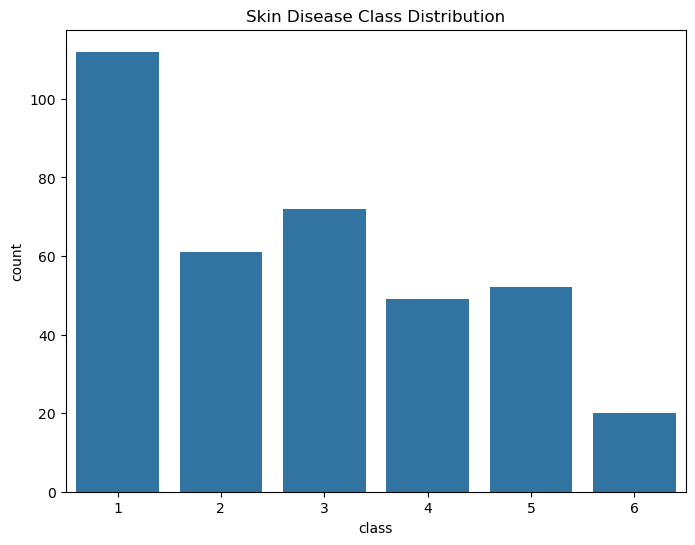

In [22]:
# 1. Class distribution
plt.figure(figsize=(8,6))
sns.countplot(x=Y)
plt.title("Skin Disease Class Distribution")
plt.show()

### **Correlation Heatmap**
* Purpose: Displays the correlation between clinical features (e.g., erythema, scaling, itching).

* Explanation: Helps identify which features are strongly related to each other or to the target variable. For example, erythema and scaling may show high correlation, suggesting they often occur together in certain diseases.

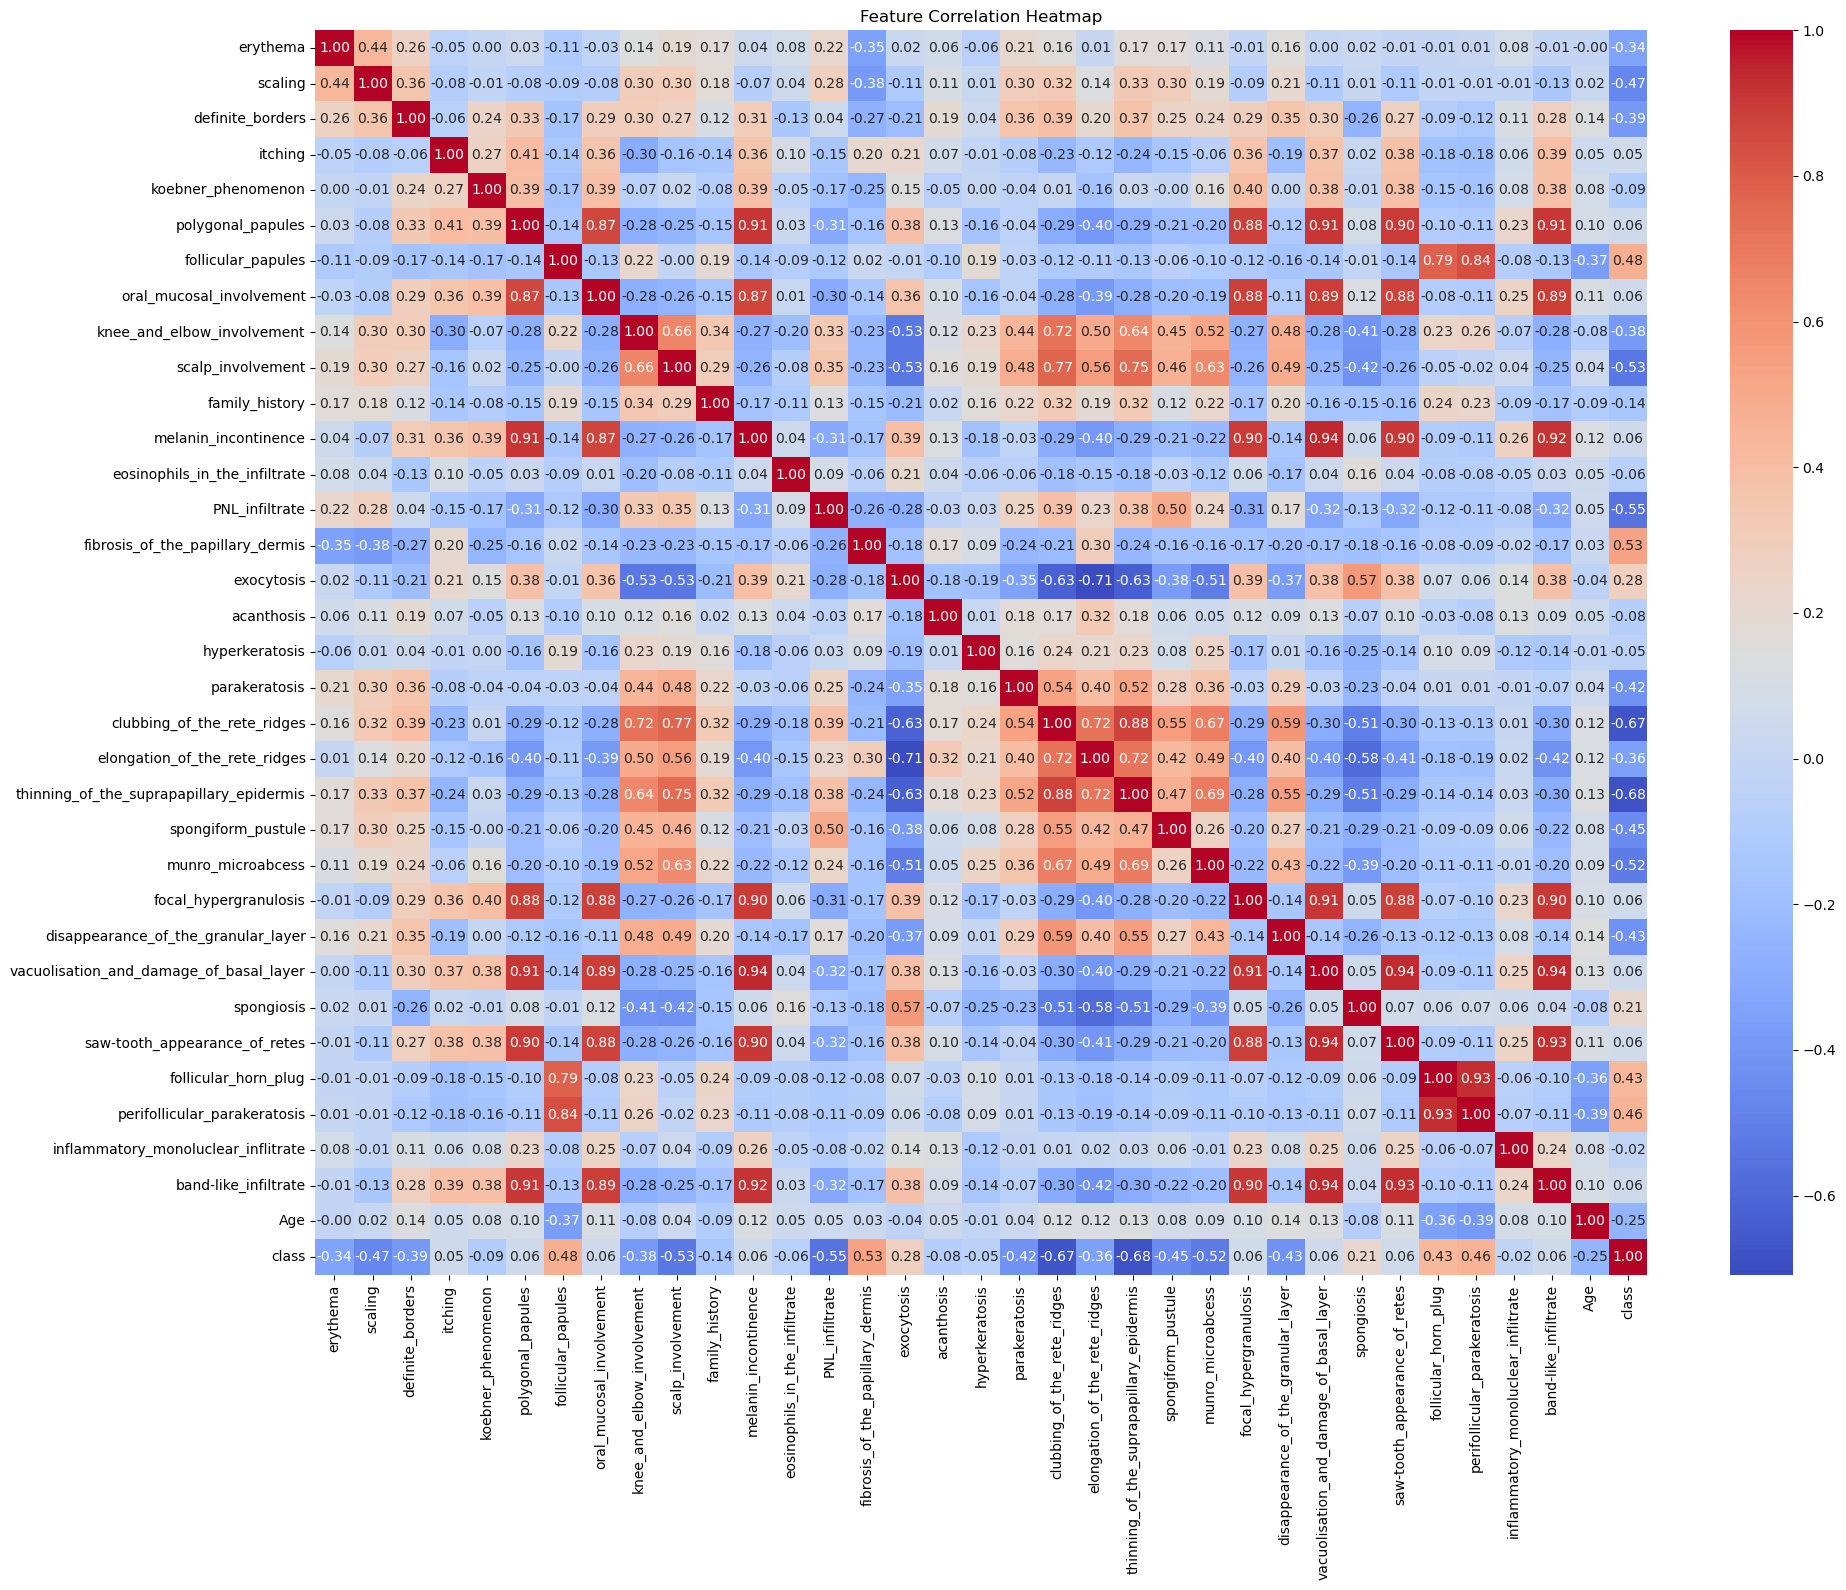

In [23]:
plt.figure(figsize=(20,16))
sns.heatmap(df.corr(), annot=True,fmt=".2f", cmap="coolwarm")
plt.title("Feature Correlation Heatmap")
plt.tight_layout()
plt.show()

### **Histograms**
* Purpose: Show the distribution of individual features (e.g., erythema, itching).

* Explanation: Helps understand the spread of values, detect skewness, and identify outliers. For instance, a histogram of “Age” can reveal whether most patients fall into a particular age group.

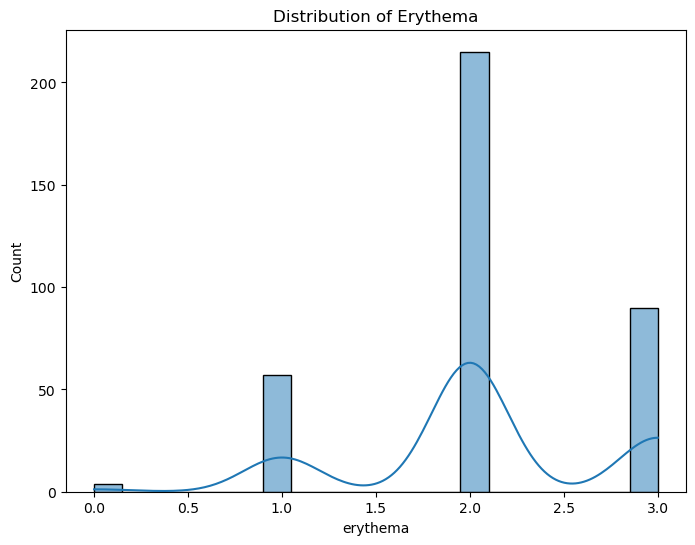

In [24]:
# 3. Histogram of erythema
plt.figure(figsize=(8,6))
sns.histplot(df['erythema'], bins=20, kde=True)
plt.title("Distribution of Erythema")
plt.show()

### **Boxplots**
* Purpose: Compare feature values across different disease classes.

* Explanation: Useful for spotting differences in symptom severity between classes. For example, itching levels may be higher in psoriasis compared to lichen planus. Boxplots also highlight outliers.

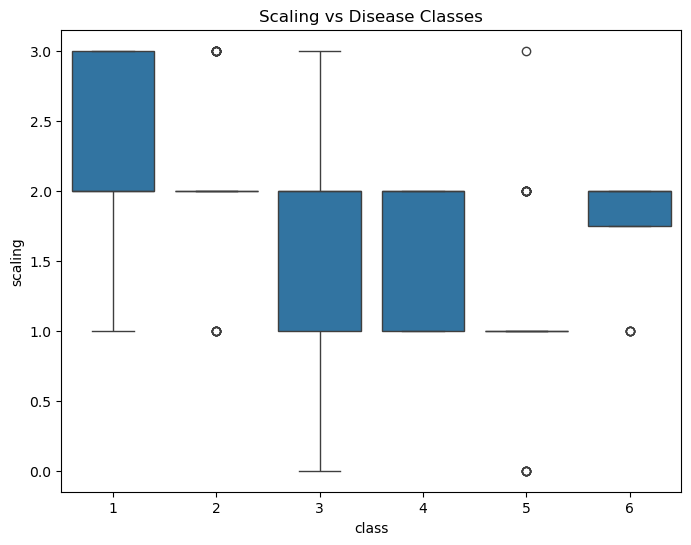

In [25]:
# 4. Boxplot of scaling vs class
plt.figure(figsize=(8,6))
sns.boxplot(x=Y, y=df['scaling'])
plt.title("Scaling vs Disease Classes")
plt.show()

### **Pairplots (Scatterplot Matrix)**
* Purpose: Visualize interactions between pairs of features.

* Explanation: Shows how two features vary together across different classes. For instance, plotting erythema vs. scaling can reveal clusters that correspond to specific diseases.

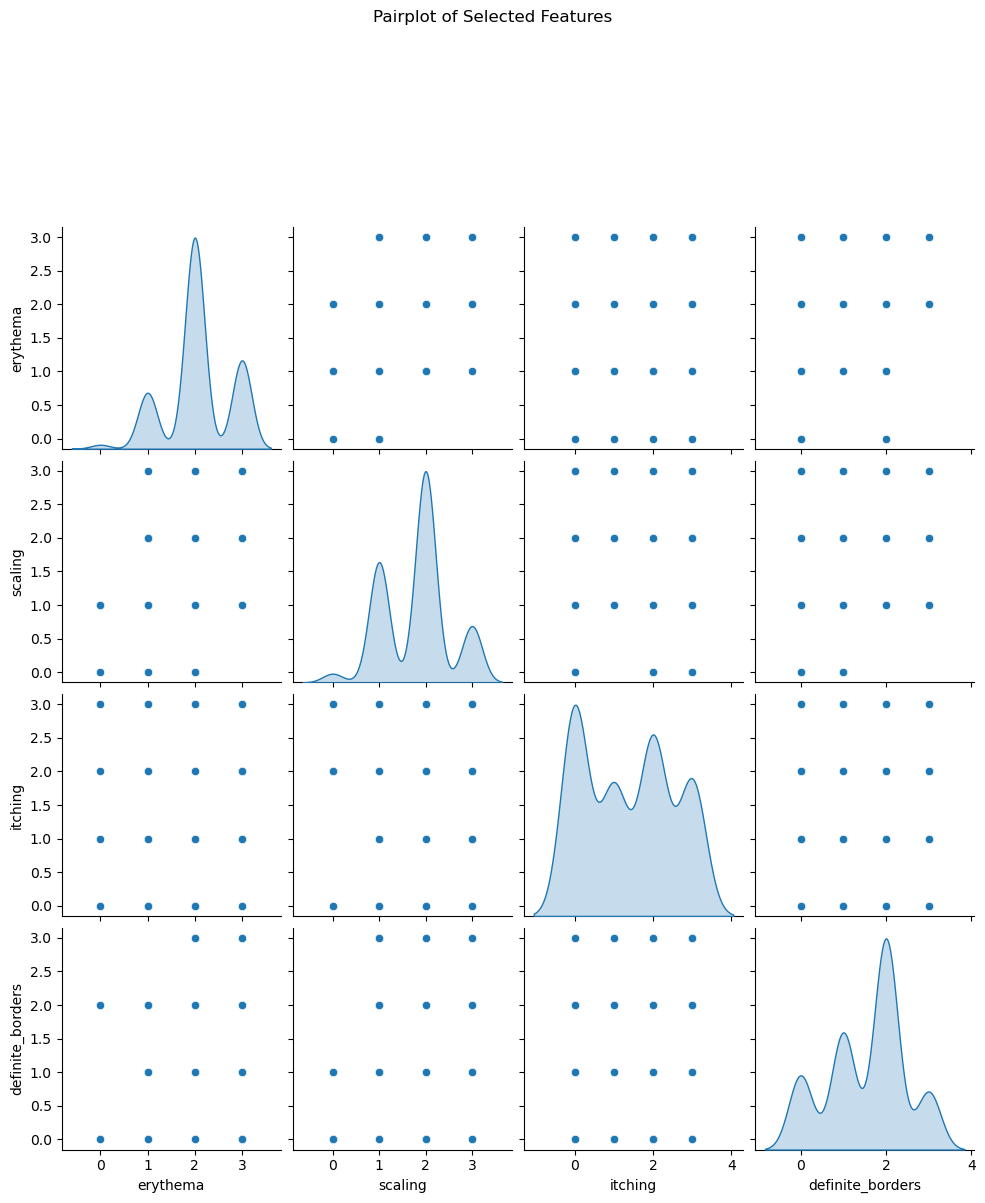

In [26]:
# 5. Pairplot of selected features
sns.pairplot(df[['erythema','scaling','itching','definite_borders']], diag_kind='kde')
plt.suptitle("Pairplot of Selected Features", y=1.2)
plt.show()

### **Barplots**
* Purpose: Show average values of important features per disease class.

* Explanation: Makes it easy to compare how symptoms differ across classes. For example, average erythema levels may be highest in psoriasis, while oral mucosal involvement is more common in lichen planus.

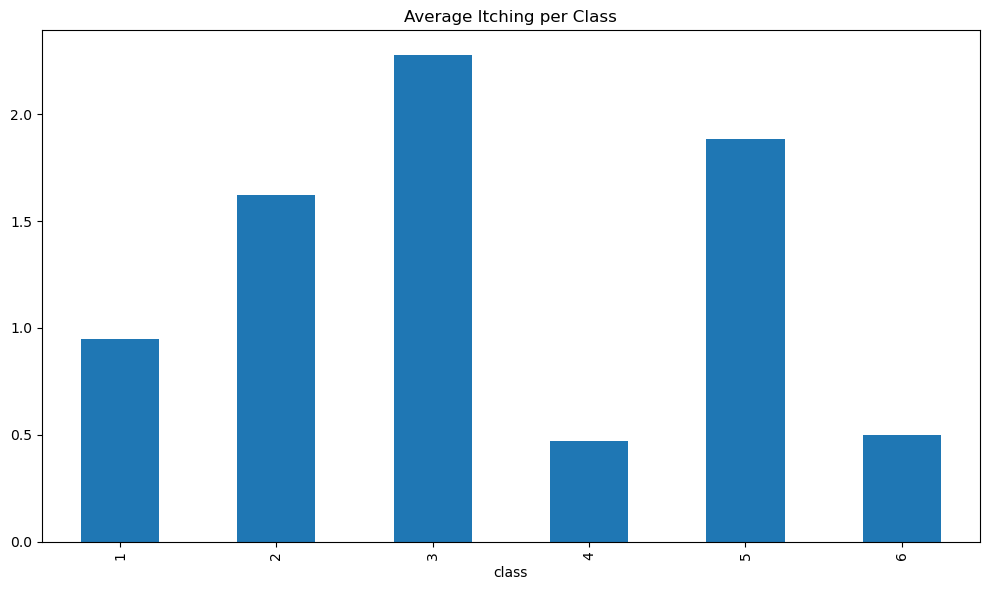

In [27]:
# 6. Barplot of average itching per class
plt.figure(figsize=(10,6))
df.groupby(Y).mean()['itching'].plot(kind='bar')
plt.title("Average Itching per Class")
plt.tight_layout()
plt.show()

## **Choice of Models**
### **Logistic Regression (Baseline Model)**

* **Why chosen:** Simple, interpretable, and effective for binary/multiclass classification problems. It provides clear coefficients that show how each feature contributes to predictions.

* **Why not others:** Purely linear models like Linear Discriminant Analysis (LDA) assume strong distributional conditions (normality, equal covariance), which may not hold in medical datasets. Logistic Regression is more flexible.

### **Random Forest Classifier**

* **Why chosen:** Handles non-linear relationships, works well with tabular data, and provides feature importance for interpretability. It is robust to noise and overfitting due to ensemble averaging.

* **Why not others:** Simple decision trees tend to overfit and lack generalization. Random Forest improves stability by combining many trees.

### **Support Vector Machine (SVM)**

* **Why chosen:** Effective in high-dimensional spaces and can separate complex boundaries using kernel tricks. Useful when features interact in non-linear ways.

* **Why not others:** K-Nearest Neighbors (KNN) is sensitive to noise and scales poorly with large datasets. SVM is more powerful and mathematically grounded for classification.

### **Gradient Boosting (XGBoost/LightGBM)**

* **Why chosen:** State-of-the-art for structured/tabular data, capable of capturing subtle patterns and interactions. It often achieves higher accuracy than other models.

* **Why not others:** Naïve Bayes assumes feature independence, which is unrealistic for medical data where symptoms are correlated. Gradient Boosting is more flexible and accurate.

In [28]:
models = {
    'LogisticRegression' : LogisticRegression(max_iter=1000, class_weight='balanced'),
    'Random Forest' : RandomForestClassifier(class_weight='balanced'),
    'SVM' : SVC(probability=True, class_weight='balanced'),
    'GradientBoosting' : GradientBoostingClassifier()
}

In [29]:
result = {}

In [30]:
for name, model in models.items():
    model.fit(X_train, Y_train)
    y_pred = model.predict(X_test)
    acc = accuracy_score(Y_test, y_pred)
    f1 = classification_report(Y_test, y_pred, output_dict=True)['weighted avg']['f1-score']
    result[name] = {"Accuracy" : acc, "F1-score":f1}
    print(f"\n{name} Results:-")
    print(classification_report(Y_test, y_pred))
    print("Confusion Matrix:\n", confusion_matrix(Y_test, y_pred))


LogisticRegression Results:-
              precision    recall  f1-score   support

           1       1.00      1.00      1.00        23
           2       1.00      0.83      0.91        12
           3       1.00      0.93      0.97        15
           4       0.77      1.00      0.87        10
           5       1.00      1.00      1.00        10
           6       1.00      1.00      1.00         4

    accuracy                           0.96        74
   macro avg       0.96      0.96      0.96        74
weighted avg       0.97      0.96      0.96        74

Confusion Matrix:
 [[23  0  0  0  0  0]
 [ 0 10  0  2  0  0]
 [ 0  0 14  1  0  0]
 [ 0  0  0 10  0  0]
 [ 0  0  0  0 10  0]
 [ 0  0  0  0  0  4]]

Random Forest Results:-
              precision    recall  f1-score   support

           1       1.00      1.00      1.00        23
           2       0.90      0.75      0.82        12
           3       1.00      1.00      1.00        15
           4       0.82      0.90      

#### According to above predictions 
Best Performing Model: SVM

Highest accuracy (97%)

Highest macro average F1-score (0.97)

Balanced performance across all classes

### Based on the held-out test set, SVM achieved the highest accuracy (97.30%) and weighted F1-score (97.30%) among the four evaluated classifiers. It was therefore selected as the best-performing model in this experiment.

## Hyperparameter Tuning with GridSearchCV and RandomizedSearchCV
* Machine learning models often depend on hyperparameters (e.g., number of trees in Random Forest, regularization strength in Logistic Regression, kernel type in SVM). Choosing the right hyperparameters is critical for achieving the best performance.

### **1. GridSearchCV**
* **What it does:** Exhaustively searches through all possible combinations of hyperparameters you specify.

* **Why used:**

* Ensures the model is tested on every possible parameter setting.

* Guarantees finding the best combination within the defined grid.

* Useful when the parameter space is small and manageable.

### **2. RandomizedSearchCV**
* **What it does:** Randomly samples combinations of hyperparameters from a defined distribution.

* **Why used:**

* Much faster than GridSearch when the parameter space is large.

* Provides a good approximation of the best parameters without testing every single combination.

* Useful for complex models like Random Forest or Gradient Boosting, where parameters (e.g., n_estimators, max_depth, min_samples_split) have wide ranges.

## **Why Both Were Used**
* **GridSearchCV →** Best for simpler models (Logistic Regression, SVM) where the parameter space is small.

* **RandomizedSearchCV →** Best for complex models (Random Forest, Gradient Boosting) where exhaustive search would be too slow.

Together, they ensure optimal tuning across all models while balancing accuracy and efficiency.

In [31]:
param_grid_lr = {'C':[0.01,0.1,1,10]}
grid_lr = GridSearchCV(LogisticRegression(max_iter=1000, class_weight='balanced'), param_grid_lr, cv=5)
grid_lr.fit(X_train, Y_train)
print("\nBest Logistic Regression Params:", grid_lr.best_params_)


Best Logistic Regression Params: {'C': 0.01}


In [32]:
param_dist_rf = {
    'n_estimators': [100,200,300],
    'max_depth': [None,10,20,30],
    'min_samples_split': [2,5,10]
}

In [33]:
rand_rf = RandomizedSearchCV(RandomForestClassifier(class_weight='balanced'), param_dist_rf, cv=5, n_iter=5, random_state=42)
rand_rf.fit(X_train, Y_train)
print("\nBest Random Forest Params:", rand_rf.best_params_)


Best Random Forest Params: {'n_estimators': 200, 'min_samples_split': 10, 'max_depth': 10}


* **ROC (Receiver Operating Characteristic)** curves are used to evaluate the performance of classification models.

* They show the trade-off between True Positive Rate (Sensitivity/Recall) and False Positive Rate (1 - Specificity) at different threshold values.

* Each curve represents how well a model distinguishes between positive and negative classes.

* The diagonal line (baseline) represents a random classifier; any model performing better will have its curve above this line.

* Comparing ROC curves of multiple models helps identify which model achieves superior classification performance.

* The closer the curve is to the top-left corner, the better the model’s predictive ability.

* ROC curves are especially useful in medical datasets, as they highlight how models balance sensitivity (detecting disease cases) and specificity (avoiding false alarms).

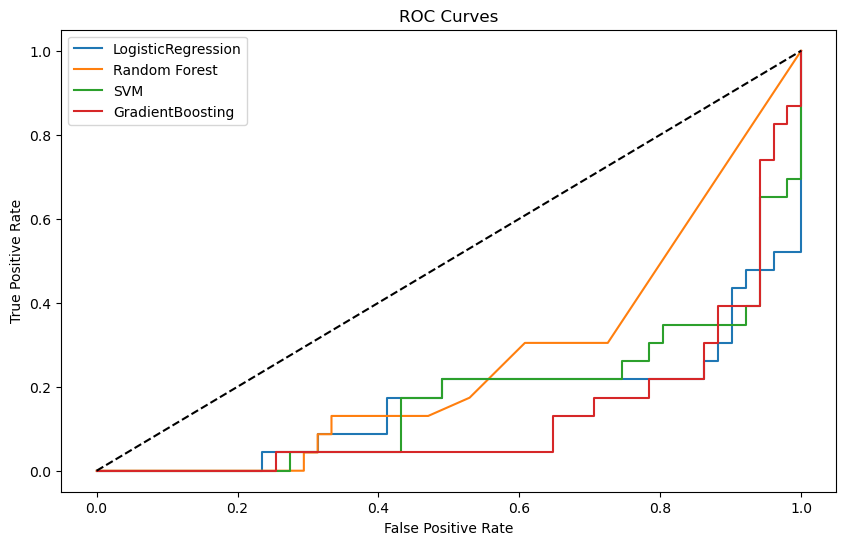

In [34]:
plt.figure(figsize=(10,6))
for name, model in models.items():
    y_prob = model.predict_proba(X_test)[:,1]
    fpr, tpr, _ = roc_curve(Y_test, y_prob, pos_label=1)
    plt.plot(fpr, tpr, label=name)
plt.plot([0,1],[0,1],'k--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves")
plt.legend()
plt.show()

In [35]:
results_df = pd.DataFrame(result).T
print("\nModel Comparison:\n", results_df)

# Doctor Suggestions
# Feature importance from Random Forest
importances = models["Random Forest"].feature_importances_
feature_names = X.columns
importance_df = pd.DataFrame({"Feature": feature_names, "Importance": importances})
importance_df = importance_df.sort_values(by="Importance", ascending=False)

print("\nTop Predictive Features for Doctors:\n", importance_df.head(10))


Model Comparison:
                     Accuracy  F1-score
LogisticRegression  0.959459  0.960642
Random Forest       0.945946  0.945205
SVM                 0.972973  0.972973
GradientBoosting    0.932432  0.930944

Top Predictive Features for Doctors:
                                      Feature  Importance
14          fibrosis_of_the_papillary_dermis    0.096372
30              perifollicular_parakeratosis    0.067600
4                         koebner_phenomenon    0.066789
29                      follicular_horn_plug    0.061236
21  thinning_of_the_suprapapillary_epidermis    0.057996
20             elongation_of_the_rete_ridges    0.051567
27                                spongiosis    0.050266
19               clubbing_of_the_rete_ridges    0.046763
32                      band-like_infiltrate    0.045148
26   vacuolisation_and_damage_of_basal_layer    0.044228


## Suggestions for Doctors

In [39]:
# Suggestions
print("\nDoctor Suggestions:")

print("- The Random Forest model identified fibrosis of the papillary dermis, Koebner phenomenon, clubbing of the rete ridges, perifollicular parakeratosis and spongiosis among the highest-ranked features.")

print("- These features represent variables that contributed relatively strongly to the Random Forest's predictions.")

print("-The findings may help identify patterns within the dataset, but they should not be interpreted as independent clinical diagnostic criteria. ")

print("- The machine-learning model should be considered a decision-support experiment and not a replacement for professional clinical diagnosis..")


Doctor Suggestions:
- The Random Forest model identified fibrosis of the papillary dermis, Koebner phenomenon, clubbing of the rete ridges, perifollicular parakeratosis and spongiosis among the highest-ranked features.
- These features represent variables that contributed relatively strongly to the Random Forest's predictions.
-The findings may help identify patterns within the dataset, but they should not be interpreted as independent clinical diagnostic criteria. 
- The machine-learning model should be considered a decision-support experiment and not a replacement for professional clinical diagnosis..


# Model Comparision
### **Model Comparison Table**

* The results from different machine learning models (Logistic Regression, Random Forest, SVM, Gradient Boosting) were stored in a dictionary.

* This dictionary was converted into a DataFrame (results_df) for easy visualization and comparison.

* The table highlights each model’s performance metrics (accuracy, precision, recall, F1-score), allowing direct comparison across models.

## **Challenges Faced During Skin Disorder Type Prediction Project**

### **Data Quality Issues**

* **Challenge:** The dataset contained invalid or non-numeric entries in the Age column and missing values across multiple features.

* **Technique Used:** Converted Age to numeric using pd.to_numeric(errors='coerce') and applied median imputation to fill missing values.

* **Reason:** Median is less sensitive to outliers compared to mean, ensuring robust handling of missing data.

### **Categorical Data Handling**

* **Challenge:** The family_history column contained categorical values (yes/no) which machine learning models cannot process directly.

* **Technique Used:** Applied binary encoding (yes → 1, no → 0).

* **Reason:** Simplifies categorical data into numeric format, making it compatible with ML algorithms while preserving meaning.

### **Class Imbalance**

* **Challenge:** Some skin disease classes had fewer samples compared to others, leading to biased predictions.

* **Technique Used:** Implemented SMOTE (Synthetic Minority Oversampling Technique).

* **Reason:** SMOTE generates synthetic samples for minority classes, balancing the dataset and improving recall and F1-score for underrepresented diseases.

### **Model Selection and Hyperparameter Tuning**

* **Challenge:** Different models performed variably across classes, and tuning hyperparameters manually was inefficient.

* **Technique Used:** Applied GridSearchCV for simpler models (Logistic Regression, SVM) and RandomizedSearchCV for complex models (Random Forest, Gradient Boosting).

* **Reason:** GridSearchCV ensures exhaustive search in small parameter spaces, while RandomizedSearchCV efficiently explores large parameter spaces without excessive computation.

### **Evaluation and Interpretability**

* **Challenge:** Doctors require not only predictions but also insights into which features are most important.

* **Technique Used:** Extracted feature importance from Random Forest and ranked top predictors.

* **Reason:** Provides actionable suggestions for doctors, bridging machine learning outputs with clinical decision-making.

### **Visualization and Communication**

* **Challenge:** Communicating results effectively to non-technical stakeholders.

* **Technique Used:** Created EDA graphs (histograms, boxplots, correlation heatmaps, ROC curves) and confusion matrices.

* **Reason:** Visualizations make complex data patterns and model performance easier to understand, supporting transparency and trust.



### Doctor Suggestions Using Feature Importance

* Random Forest provides a measure of feature importance, showing which clinical attributes contribute most to disease classification.

* The code extracts these importance values and pairs them with the corresponding feature names.

* A sorted DataFrame (importance_df) ranks features from most to least important.

* The top 10 predictive features are displayed, giving doctors insight into which symptoms (e.g., erythema, scaling, itching, family history) are most influential in diagnosis.

# Conclusion
- This project analyzed a skin-disorder dataset containing 366 observations, 34 predictor variables and six disease classes. The data-analysis stage involved data cleaning, missing-value handling, feature inspection and exploratory visualization. The analysis identified class imbalance, which was addressed during model development using SMOTE on the training data.

- Four machine-learning algorithms—Logistic Regression, Random Forest, SVM and Gradient Boosting—were evaluated. Among the models tested, SVM achieved the highest test accuracy and weighted F1-score of 97.30%, making it the best-performing model in this experiment.

- Feature-importance analysis using Random Forest identified several clinical and histopathological variables that contributed strongly to its predictions. However, these results represent patterns learned from the available dataset and should not be interpreted as causal or clinically validated diagnostic indicators.

- Overall, the project demonstrates how data analysis and machine learning can be applied to multiclass skin-disorder classification. Because the dataset is relatively small and no independent clinical validation has been performed, the model should be considered an academic demonstration rather than a clinically validated diagnostic system.